# Clarillo Predice: riesgo de incendio en el entorno del Parque Nacional Río Clarillo

- **Actividad A+S:** Taller de Analítica Predictiva y Prescriptiva (IDA602)
- **Estudiante:** Alejandro Espinoza
- **Socio comunitario:** guardaparque del Parque Nacional Río Clarillo (CONAF), comuna de Pirque

Este notebook reúne los datos y los modelos de la etapa de ejecución. Responde a los tres objetivos del proyecto:

| Objetivo | Meta | Sección |
|---|---|---|
| 1. Identificar las variables que explican los incendios en el entorno de Pirque | ranking de al menos 10 variables | 5 |
| 2. Modelos que estimen cuándo y dónde es más probable un incendio | AUC ≥ 0,75 en prueba, superar las reglas de CONAF y un mapa cuyo 20% del área concentre al menos el 50% de los incendios | 3, 4 y 6 |
| 3. Boletín semanal con IA generativa y pronóstico de 7 días | boletín enviado por correo al equipo del parque | 7 |

Los datos se cargan desde GitHub, por lo que el notebook se puede ejecutar completo en Google Colab sin archivos locales.

### Cómo ejecutar

1. **Activar la GPU (recomendado):** menú **Entorno de ejecución → Cambiar tipo de entorno → T4 GPU → Guardar** (en inglés: **Runtime → Change runtime type → T4 GPU → Save**). Es gratuita y hace que el boletín se redacte en segundos.
2. **Ejecutar todo:** **Entorno de ejecución → Ejecutar todo** (en inglés: **Runtime → Run all**).
3. **Correo:** al final, el notebook pide el correo de destino. Si se deja vacío, el boletín solo se guarda como archivo HTML.

La primera ejecución tarda unos minutos, porque descarga el modelo de IA de código abierto (Qwen2.5).

In [54]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, precision_recall_curve, RocCurveDisplay)

## 1. Datos

Los datos se prepararon en la primera parte de la ejecución, a partir de fuentes públicas:

- **Incendios CONAF** 2002-03 a 2024-25: registro histórico de Datos para Resiliencia (2002-2020) y capas SIMEF (2020-2025), con fecha y coordenadas de cada incendio.
- **Clima Open-Meteo** (reanálisis ERA5) diario y por hora, en un punto cercano al parque. Se validó con la estación DGA de Pirque.
- **Índices de CONAF** calculados con el clima de la tarde: humedad del combustible fino muerto (HCFM), probabilidad de ignición (PI), regla 30-30-30 y una aproximación del Botón Rojo.
- **Territorio** en celdas de 2 x 2 km: relieve (SRTM), vegetación (NDVI MODIS), caminos y edificaciones (OpenStreetMap).

Se usan tres archivos:

| Archivo | Contenido |
|---|---|
| `dataset_incendios_pirque_diario.csv` | un día por fila (8.240 días), con la variable objetivo y 36 variables |
| `incendios_entorno.csv` | los 888 incendios a 25 km o menos del parque, con fecha, causa y celda |
| `celdas_entorno.csv` | las 484 celdas de 2 x 2 km del entorno, con sus características |

In [55]:
url_base = "https://raw.githubusercontent.com/alejandro7espinoza-star/clarillo-predice/main/"

df = pd.read_csv(url_base + "dataset_incendios_pirque_diario.csv", parse_dates=["fecha"])
incendios = pd.read_csv(url_base + "incendios_entorno.csv", parse_dates=["fecha"])
celdas = pd.read_csv(url_base + "celdas_entorno.csv")

print("Días:", df.shape, "| desde", df["fecha"].min().date(), "hasta", df["fecha"].max().date())
print("Incendios en el entorno:", len(incendios))
print("Celdas:", len(celdas))
print("Nulos en el dataset diario:", df.isna().sum().sum())

Días: (8240, 44) | desde 2002-07-08 hasta 2025-06-30
Incendios en el entorno: 888
Celdas: 484
Nulos en el dataset diario: 0


**Variable objetivo:** `dia_critico` = 1 si ese día se inició al menos un incendio a 25 km o menos del parque.

Las columnas `n_entorno`, `dia_incendio_pirque`, `n_pirque`, `n_rm` y `sup_entorno_ha` cuentan los incendios del mismo día. No se usan como predictoras, porque el modelo conocería la respuesta.

## 2. Análisis exploratorio

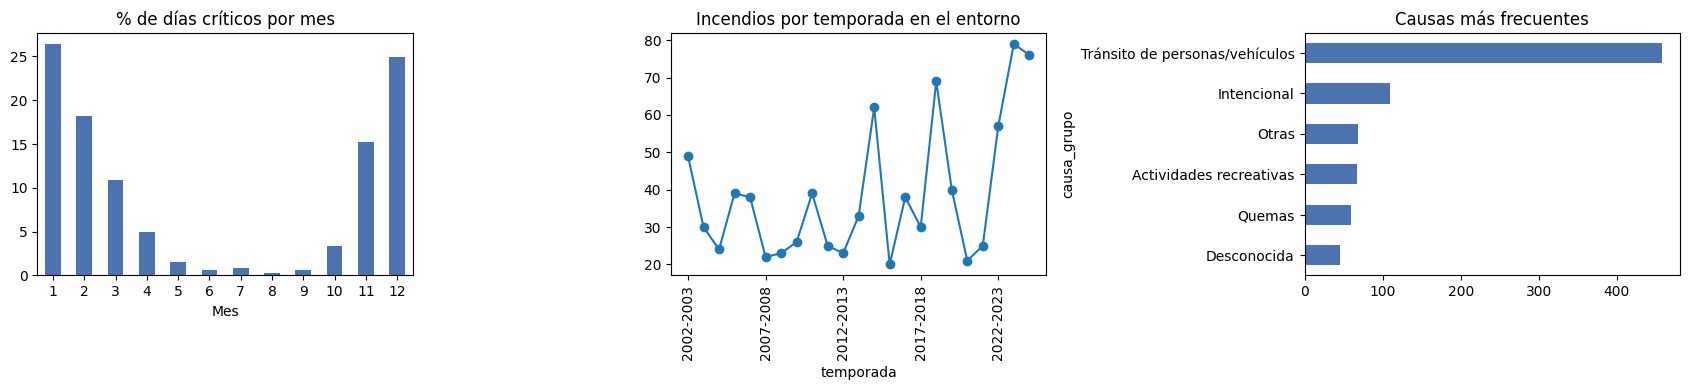

Días críticos: 9.1 %
Incendios entre noviembre y marzo: 89.9 %
Promedio por temporada 2002-2012: 31.5
Promedio por temporada 2022-2025: 70.7


In [56]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4))

(df.groupby("mes")["dia_critico"].mean() * 100).plot(kind="bar", ax=ejes[0], color="#4C72B0")
ejes[0].set_title("% de días críticos por mes")
ejes[0].set_xlabel("Mes")
ejes[0].tick_params(axis="x", rotation=0)

incendios.groupby("temporada").size().plot(ax=ejes[1], marker="o")
ejes[1].set_title("Incendios por temporada en el entorno")
ejes[1].tick_params(axis="x", rotation=90)

incendios["causa_grupo"].value_counts().head(6).iloc[::-1].plot(kind="barh", ax=ejes[2], color="#4C72B0")
ejes[2].set_title("Causas más frecuentes")
plt.tight_layout()
plt.show()

print("Días críticos:", round(df["dia_critico"].mean() * 100, 1), "%")
print("Incendios entre noviembre y marzo:", round(incendios["fecha"].dt.month.isin([11, 12, 1, 2, 3]).mean() * 100, 1), "%")
print("Promedio por temporada 2002-2012:", round(incendios[incendios["temporada"] <= "2011-2012"].groupby("temporada").size().mean(), 1))
print("Promedio por temporada 2022-2025:", round(incendios[incendios["temporada"] >= "2022-2023"].groupby("temporada").size().mean(), 1))

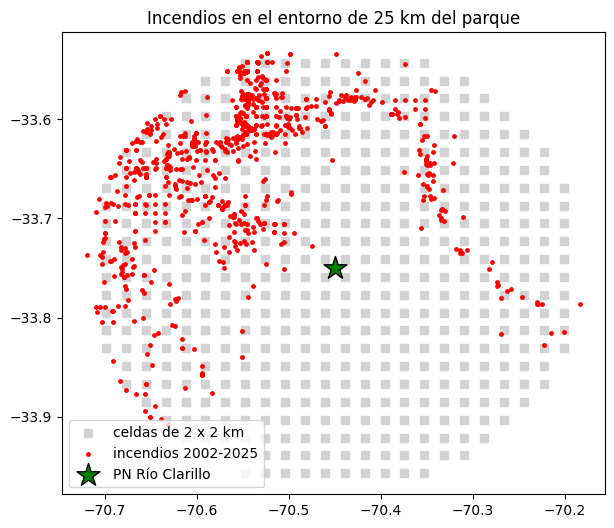

In [57]:
plt.figure(figsize=(7, 6))
plt.scatter(celdas["lon"], celdas["lat"], c="lightgray", marker="s", s=35, label="celdas de 2 x 2 km")
plt.scatter(incendios["lon"], incendios["lat"], s=6, c="red", label="incendios 2002-2025")
plt.scatter([-70.45], [-33.75], marker="*", s=300, c="green", edgecolor="k", label="PN Río Clarillo")
plt.title("Incendios en el entorno de 25 km del parque")
plt.legend(loc="lower left")
plt.show()

**Observaciones**

- Solo el 9,1% de los días son críticos: las clases están desbalanceadas, por lo que se usan AUC, PR AUC, recall y F1 en vez de accuracy.
- El 90% de los incendios ocurre entre noviembre y marzo.
- Los incendios por temporada se duplicaron: de 32 en promedio entre 2002 y 2012 a 71 en las tres últimas temporadas.
- La mayoría tiene origen humano (tránsito de personas o vehículos e intencionales) y se concentra al noroeste del parque, cerca de Puente Alto y Pirque.

## 3. Modelo de días críticos (¿cuándo?)

**Partición temporal:** se entrena con las temporadas 2002-03 a 2021-22 y se evalúa con 2022-23 a 2024-25, como se usaría en la realidad. No se mezclan días al azar.

**Modelo:** Random Forest. Se eligió comparando regresión logística, Random Forest y Gradient Boosting, y se optimizó con búsqueda de hiperparámetros (`GridSearchCV`) y validación cruzada temporal (`TimeSeriesSplit`). Aquí se usan directamente los parámetros encontrados.

**Variables agregadas:** tasa histórica de días críticos del mes (solo con entrenamiento) y el mes como ciclo (seno y coseno), para que diciembre y enero queden cerca.

In [58]:
fuga = ["n_entorno", "dia_incendio_pirque", "n_pirque", "n_rm", "sup_entorno_ha"]
datos = df.drop(columns=fuga).sort_values("fecha").reset_index(drop=True)

train = datos[datos["temporada"] <= "2021-2022"]
tasa_mes = train.groupby("mes")["dia_critico"].mean()
datos["tasa_mes"] = datos["mes"].map(tasa_mes)
datos["mes_sin"] = np.sin(2 * np.pi * datos["mes"] / 12)
datos["mes_cos"] = np.cos(2 * np.pi * datos["mes"] / 12)

variables = [c for c in datos.columns if c not in ["fecha", "temporada", "dia_critico"]]
train = datos[datos["temporada"] <= "2021-2022"]
test = datos[datos["temporada"] >= "2022-2023"]
X_train, y_train = train[variables], train["dia_critico"]
X_test, y_test = test[variables], test["dia_critico"]

print("Variables predictoras:", len(variables))
print("Entrenamiento:", X_train.shape, "| días críticos:", round(y_train.mean(), 3))
print("Prueba:", X_test.shape, "| días críticos:", round(y_test.mean(), 3))

Variables predictoras: 39
Entrenamiento: (7165, 39) | días críticos: 0.081
Prueba: (1075, 39) | días críticos: 0.158


In [59]:
parametros = {"n_estimators": 200, "max_depth": 5, "min_samples_leaf": 50, "max_features": "sqrt",
              "class_weight": None, "random_state": 42, "n_jobs": -1}

# Umbral de alerta: se elige en las últimas 3 temporadas de entrenamiento, maximizando el F1
ajuste = train[train["temporada"] <= "2018-2019"]
validacion = train[train["temporada"] >= "2019-2020"]
modelo = RandomForestClassifier(**parametros).fit(ajuste[variables], ajuste["dia_critico"])
prob_val = modelo.predict_proba(validacion[variables])[:, 1]
precision, recall, cortes_pr = precision_recall_curve(validacion["dia_critico"], prob_val)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-9)
umbral = round(float(cortes_pr[np.argmax(f1)]), 3)

# Modelo final entrenado con todo el entrenamiento y evaluado en prueba
modelo = RandomForestClassifier(**parametros).fit(X_train, y_train)
prob_train = modelo.predict_proba(X_train)[:, 1]
prob_test = modelo.predict_proba(X_test)[:, 1]
alerta = (prob_test >= umbral).astype(int)

print("Umbral de alerta:", umbral)
print("AUC entrenamiento:", round(roc_auc_score(y_train, prob_train), 3))
print("AUC prueba:", round(roc_auc_score(y_test, prob_test), 3), "(meta ≥ 0,75)")
print("PR AUC prueba:", round(average_precision_score(y_test, prob_test), 3), "| azar:", round(y_test.mean(), 3))
print("Recall:", round(recall_score(y_test, alerta), 3), "| Precision:", round(precision_score(y_test, alerta), 3),
      "| F1:", round(f1_score(y_test, alerta), 3))

Umbral de alerta: 0.195
AUC entrenamiento: 0.863
AUC prueba: 0.854 (meta ≥ 0,75)
PR AUC prueba: 0.441 | azar: 0.158
Recall: 0.612 | Precision: 0.441 | F1: 0.512


### 3.1 Comparación con las reglas de CONAF

- **Botón Rojo (aproximado):** probabilidad de ignición ≥ 70% y viento ≥ 20 km/h en la tarde.
- **30-30-30:** 2 o más condiciones entre temperatura > 30 °C, humedad < 30% y viento > 30 km/h.

In [60]:
def resumen(pred, nombre):
    return {"Criterio": nombre,
            "Días alertados": int(pred.sum()),
            "Recall": round(recall_score(y_test, pred), 3),
            "Precision": round(precision_score(y_test, pred, zero_division=0), 3),
            "F1": round(f1_score(y_test, pred), 3)}

comparacion = pd.DataFrame([
    resumen(test["boton_rojo_aprox"].values, "Botón Rojo (aprox.)"),
    resumen((test["indice_30_30_30"] >= 2).astype(int).values, "30-30-30 (2 o más)"),
    resumen(alerta, "Modelo Random Forest"),
])
comparacion

,Criterio,Días alertados,Recall,Precision,F1
0,Botón Rojo (aprox.),35,0.076,0.371,0.127
1,30-30-30 (2 o más),182,0.424,0.396,0.409
2,Modelo Random Forest,236,0.612,0.441,0.512


### 3.2 Niveles de riesgo

La probabilidad se traduce en 4 niveles con los percentiles 50, 80 y 95 de las probabilidades de entrenamiento. Cada nivel tiene una acción sugerida, que se valida con el socio comunitario.

In [61]:
cortes = np.quantile(prob_train, [0.5, 0.8, 0.95])
niveles = ["Bajo", "Moderado", "Alto", "Extremo"]
acciones = {"Bajo": "Operación normal",
            "Moderado": "Difusión preventiva a visitantes y vecinos",
            "Alto": "Reforzar patrullajes en los sectores prioritarios",
            "Extremo": "Evaluar restricción de actividades o cierre, en coordinación con CONAF"}

riesgo = test[["fecha", "dia_critico"]].copy()
riesgo["prob"] = prob_test
riesgo["nivel"] = pd.cut(riesgo["prob"], [-np.inf, *cortes, np.inf], labels=niveles)

tabla_niveles = riesgo.groupby("nivel", observed=False).agg(dias=("dia_critico", "size"), criticos=("dia_critico", "sum"))
tabla_niveles["% días críticos en el nivel"] = (tabla_niveles["criticos"] / tabla_niveles["dias"] * 100).round(1)
tabla_niveles["% del total de días críticos"] = (tabla_niveles["criticos"] / riesgo["dia_critico"].sum() * 100).round(1)
tabla_niveles["Acción"] = [acciones[n] for n in tabla_niveles.index]
print("Cortes de probabilidad:", cortes.round(3))
tabla_niveles

Cortes de probabilidad: [0.041 0.165 0.266]


,dias,criticos,% días críticos en el nivel,% del total de días críticos,Acción
nivel,,,,,
Bajo,531,6,1.1,3.5,Operación normal
Moderado,249,44,17.7,25.9,Difusión preventiva a visitantes y vecinos
Alto,187,69,36.9,40.6,Reforzar patrullajes en los sectores prioritarios
Extremo,108,51,47.2,30.0,"Evaluar restricción de actividades o cierre, e..."


## 4. Resultado del modelo diario

- Cumple la meta: AUC de 0,85 en las temporadas de prueba, sin sobreajuste (AUC de entrenamiento 0,86).
- Supera a las reglas de CONAF: detecta el 61% de los días críticos, frente al 42% de la regla 30-30-30 y el 8% del Botón Rojo, con mejor precisión.
- Los niveles funcionan: la tasa de días críticos sube de 1% (Bajo) a 46% (Extremo). Alto y Extremo reúnen el 27% de los días, pero el 70% de los días críticos.
- Limitación: uno de cada dos días con alerta no termina en incendio, y en marzo y abril el modelo casi no alerta.

## 5. Variables que explican los incendios (objetivo 1)

**Importancia por permutación:** se desordena una variable a la vez en prueba y se mide cuánto cae el AUC.

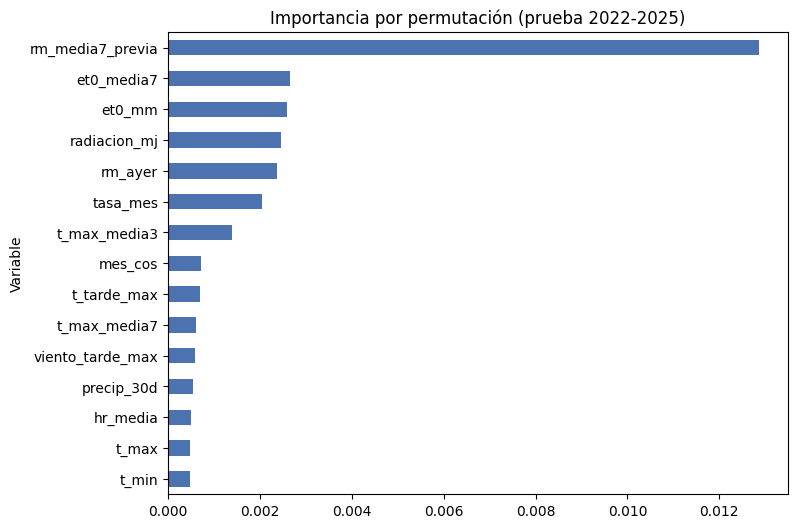

Posición de HCFM: 17 | Posición de la probabilidad de ignición: 19


,Variable,Caída AUC
1,rm_media7_previa,0.012854
2,et0_media7,0.002651
3,et0_mm,0.002579
4,radiacion_mj,0.002465
5,rm_ayer,0.002369
6,tasa_mes,0.002045
7,t_max_media3,0.001399
8,mes_cos,0.000712
9,t_tarde_max,0.000701
10,t_max_media7,0.000617


In [62]:
importancia = permutation_importance(modelo, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42, n_jobs=-1)
ranking = pd.DataFrame({"Variable": variables, "Caída AUC": importancia.importances_mean})
ranking = ranking.sort_values("Caída AUC", ascending=False).reset_index(drop=True)
ranking.index += 1

ranking.head(15).iloc[::-1].plot(x="Variable", y="Caída AUC", kind="barh", figsize=(8, 6), color="#4C72B0", legend=False)
plt.title("Importancia por permutación (prueba 2022-2025)")
plt.show()

print("Posición de HCFM:", ranking.index[ranking["Variable"] == "hcfm_tarde_min"][0],
      "| Posición de la probabilidad de ignición:", ranking.index[ranking["Variable"] == "pi_tarde_max"][0])
ranking.head(15)

- La variable más importante es el promedio de incendios en la Región Metropolitana de los 7 días previos: refleja periodos de alta actividad regional.
- Le siguen las variables de sequedad y calor: evapotranspiración, radiación, temperatura y humedad de la tarde.
- La HCFM y la probabilidad de ignición (los índices de CONAF) aportan, pero menos que la evapotranspiración, porque miden lo mismo de otra forma.
- Este ranking cumple la meta del objetivo 1 y se revisará con el socio comunitario.

## 6. Mapa de prioridad (¿dónde?)

El modelo diario dice **cuándo** tener más cuidado. Para saber **dónde**, que fue lo que más valoró el socio, se divide el entorno en celdas de 2 x 2 km.

- **Una fila por celda y temporada** (484 celdas x 22 temporadas).
- **Objetivo:** 1 si en la celda hubo al menos un incendio esa temporada.
- **Variables:** relieve, vegetación, caminos, edificaciones, distancia al parque e **incendios de temporadas anteriores** en la celda y en sus vecinas (solo temporadas pasadas, sin usar información futura).
- Misma partición temporal: entrenamiento hasta 2021-22 y prueba 2022-23 a 2024-25.

In [63]:
celdas["celda"] = celdas["i"].astype(str) + "," + celdas["j"].astype(str)
incendios["celda"] = incendios["celda_i"].astype(str) + "," + incendios["celda_j"].astype(str)
temporadas = sorted(incendios["temporada"].unique())

conteo = incendios.groupby(["celda", "temporada"]).size().unstack(fill_value=0)
conteo = conteo.reindex(index=celdas["celda"], columns=temporadas, fill_value=0)

# Celdas vecinas (las 8 que rodean a cada celda)
posicion = {c: k for k, c in enumerate(celdas["celda"])}
vecinas = []
for i, j in zip(celdas["i"], celdas["j"]):
    lista = [posicion[f"{i + a},{j + b}"] for a in (-1, 0, 1) for b in (-1, 0, 1)
             if (a or b) and f"{i + a},{j + b}" in posicion]
    vecinas.append(lista)

def historial(hasta):
    # promedio de incendios por temporada en la celda y en sus vecinas, en las temporadas anteriores a 'hasta'
    previas = [t for t in temporadas if t < hasta]
    prom = conteo[previas].mean(axis=1).values
    prom_vecinas = np.array([prom[v].mean() for v in vecinas])
    return prom, prom_vecinas

filas = []
for t in temporadas[1:] + ["2025-2026"]:
    prom, prom_vecinas = historial(t)
    tabla = celdas.copy()
    tabla["temporada"] = t
    tabla["incendios_previos"] = prom
    tabla["incendios_previos_vecinas"] = prom_vecinas
    tabla["hubo_incendio"] = (conteo[t].values > 0).astype(int) if t in conteo.columns else np.nan
    filas.append(tabla)
panel = pd.concat(filas, ignore_index=True)

var_celda = ["dist_parque_km", "elev_media_m", "elev_desv_m", "pendiente_media_g", "pendiente_max_g", "frac_ladera_norte",
             "ndvi_verano", "km_vial_principal", "km_vial_secundario", "km_calle_local", "km_huella_sendero", "edificios",
             "incendios_previos", "incendios_previos_vecinas"]
train_c = panel[panel["temporada"] <= "2021-2022"]
test_c = panel[panel["temporada"].between("2022-2023", "2024-2025")]
print("Entrenamiento:", train_c.shape, "| celdas-temporada con incendio:", round(train_c["hubo_incendio"].mean(), 3))
print("Prueba:", test_c.shape, "| celdas-temporada con incendio:", round(test_c["hubo_incendio"].mean(), 3))

Entrenamiento: (9196, 21) | celdas-temporada con incendio: 0.048
Prueba: (1452, 21) | celdas-temporada con incendio: 0.087


In [64]:
modelo_celdas = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=42, n_jobs=-1)
modelo_celdas.fit(train_c[var_celda], train_c["hubo_incendio"])
test_c = test_c.copy()
test_c["prob"] = modelo_celdas.predict_proba(test_c[var_celda])[:, 1]
print("AUC prueba (celda-temporada):", round(roc_auc_score(test_c["hubo_incendio"], test_c["prob"]), 3))

# Meta: el 20% de las celdas de mayor riesgo debe concentrar al menos el 50% de los incendios de prueba
riesgo_celda = test_c.groupby("celda")["prob"].mean()
incendios_test = incendios[incendios["temporada"] >= "2022-2023"].groupby("celda").size()
incendios_test = incendios_test.reindex(riesgo_celda.index, fill_value=0)
top20 = riesgo_celda.sort_values(ascending=False).index[: int(len(riesgo_celda) * 0.2)]
print("Incendios de prueba en el 20% de celdas de mayor riesgo:",
      round(incendios_test[top20].sum() / incendios_test.sum() * 100, 1), "% (meta ≥ 50%)")

importancia_celdas = pd.Series(modelo_celdas.feature_importances_, index=var_celda).sort_values(ascending=False)
importancia_celdas.round(3)

AUC prueba (celda-temporada): 0.901
Incendios de prueba en el 20% de celdas de mayor riesgo: 80.2 % (meta ≥ 50%)


,0
incendios_previos,0.236
incendios_previos_vecinas,0.156
km_calle_local,0.142
km_vial_principal,0.075
edificios,0.074
elev_media_m,0.067
km_vial_secundario,0.049
ndvi_verano,0.042
pendiente_media_g,0.038
pendiente_max_g,0.032


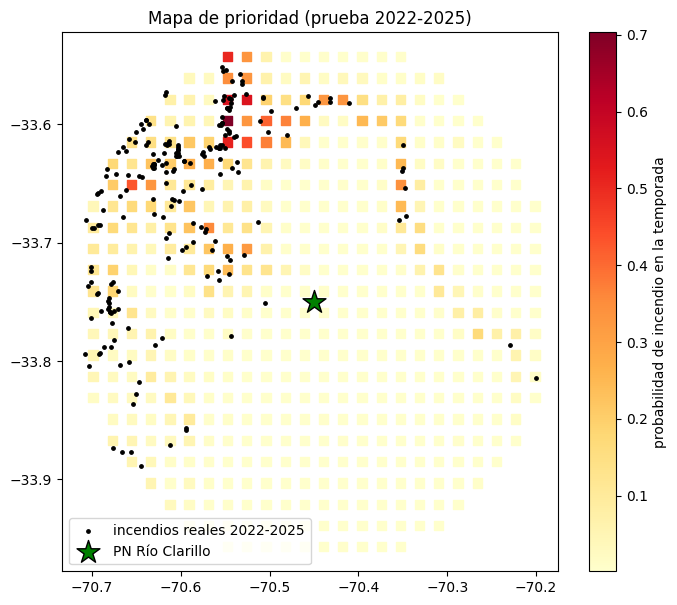

,celdas,incendios reales
prioridad,,
Baja,242,1
Media,145,40
Alta,72,108
Muy alta,25,58


In [65]:
mapa = celdas.set_index("celda").loc[riesgo_celda.index, ["lat", "lon"]]
mapa["riesgo"] = riesgo_celda
mapa["prioridad"] = pd.qcut(mapa["riesgo"], [0, 0.5, 0.8, 0.95, 1], labels=["Baja", "Media", "Alta", "Muy alta"])
inc_test = incendios[incendios["temporada"] >= "2022-2023"]

plt.figure(figsize=(8, 7))
plt.scatter(mapa["lon"], mapa["lat"], c=mapa["riesgo"], cmap="YlOrRd", marker="s", s=45)
plt.colorbar(label="probabilidad de incendio en la temporada")
plt.scatter(inc_test["lon"], inc_test["lat"], s=6, c="k", label="incendios reales 2022-2025")
plt.scatter([-70.45], [-33.75], marker="*", s=300, c="green", edgecolor="k", label="PN Río Clarillo")
plt.title("Mapa de prioridad (prueba 2022-2025)")
plt.legend(loc="lower left")
plt.show()

resumen_prioridad = mapa.groupby("prioridad", observed=False).agg(celdas=("riesgo", "size"))
resumen_prioridad["incendios reales"] = incendios_test.groupby(mapa["prioridad"], observed=False).sum()
resumen_prioridad

- AUC de 0,90 en prueba. El 20% de las celdas de mayor riesgo concentró el 80% de los incendios de 2022-2025, muy por sobre la meta del 50%. Las celdas de prioridad Baja (la mitad del área) tuvieron solo 1 incendio.
- Lo que más pesa son los incendios previos de la celda y sus vecinas, la cercanía a calles, huellas y edificaciones, y la menor altura: los incendios ocurren donde hay personas.
- Para el boletín, el riesgo de cada sector en un día se obtiene combinando ambos modelos: probabilidad del día x probabilidad de la celda.

## 7. Boletín semanal con pronóstico de 7 días (objetivo 3)

El socio pidió anticipar los próximos 7 días y recibir el boletín por correo. El proceso:

1. Descargar el pronóstico de Open-Meteo para el mismo punto de los datos de entrenamiento.
2. Calcular las mismas variables del modelo diario y estimar el riesgo de cada día.
3. Tomar las celdas de mayor riesgo de la temporada actual (mapa de prioridad), en todo el entorno y dentro de Pirque.
4. Redactar el texto con **Qwen2.5**, un modelo de IA generativa de código abierto (licencia Apache 2.0) que corre dentro de Colab, sin clave ni cuenta. Con GPU se usa la versión de 1.5B; sin GPU, la de 0.5B, más rápida pero de redacción más simple.
5. Guardar el boletín en HTML y enviarlo por correo.

In [66]:
import requests
import holidays
from datetime import timedelta

hoy = pd.Timestamp.today().normalize()
diarias = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "precipitation_sum",
           "relative_humidity_2m_max", "relative_humidity_2m_min", "relative_humidity_2m_mean", "wind_speed_10m_max",
           "wind_gusts_10m_max", "wind_direction_10m_dominant", "et0_fao_evapotranspiration", "shortwave_radiation_sum"]
horarias = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "wind_gusts_10m", "precipitation",
            "vapour_pressure_deficit", "shortwave_radiation"]

pronostico = requests.get("https://api.open-meteo.com/v1/forecast", timeout=60, params={
    "latitude": -33.72, "longitude": -70.47, "daily": ",".join(diarias), "hourly": ",".join(horarias),
    "past_days": 31, "forecast_days": 7, "timezone": "America/Santiago"}).json()
historico = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=60, params={
    "latitude": -33.72, "longitude": -70.47, "daily": "precipitation_sum", "timezone": "America/Santiago",
    "start_date": str((hoy - timedelta(days=300)).date()), "end_date": str((hoy - timedelta(days=32)).date())}).json()

clima = pd.DataFrame(pronostico["daily"])
clima.columns = ["fecha", "t_max", "t_min", "t_media", "precip_mm", "hr_max", "hr_min", "hr_media",
                 "viento_max_kmh", "rafaga_max_kmh", "viento_dir", "et0_mm", "radiacion_mj"]
clima["fecha"] = pd.to_datetime(clima["fecha"])
hora = pd.DataFrame(pronostico["hourly"])
hora.columns = ["fecha_hora", "temp", "hr", "viento_kmh", "rafaga_kmh", "precip_mm", "vpd_kpa", "radiacion_wm2"]
hora["fecha_hora"] = pd.to_datetime(hora["fecha_hora"])
lluvia_previa = pd.DataFrame({"fecha": pd.to_datetime(historico["daily"]["time"]),
                              "precip_mm": historico["daily"]["precipitation_sum"]})
print("Pronóstico desde", clima["fecha"].min().date(), "hasta", clima["fecha"].max().date())

Pronóstico desde 2026-10-14 hasta 2026-11-20


Mismos cálculos usados para construir el dataset: condiciones de la tarde (14 a 18:59 h) con HCFM y probabilidad de ignición, días sin lluvia, medias móviles, regla 30-30-30 y calendario. Los incendios de los días previos se reemplazan por el promedio histórico del mes, porque no se conocen para los días futuros.

In [67]:
def hcfm(t, hr):
    # Humedad del combustible fino muerto (ecuaciones de Simard, t en °F)
    t_f = t * 9 / 5 + 32
    emc = np.where(hr < 10, 0.03229 + 0.281073 * hr - 0.000578 * hr * t_f,
          np.where(hr < 50, 2.22749 + 0.160107 * hr - 0.01478 * t_f,
                   21.0606 + 0.005565 * hr ** 2 - 0.00035 * hr * t_f - 0.483199 * hr))
    return 1.03 * emc

def prob_ignicion(t, m):
    q = 144.5 - 0.266 * t - 0.00058 * t ** 2 - 0.01 * t * m + 18.54 * (1 - np.exp(-0.151 * m)) + 6.4 * m
    x = np.clip((400 - q) / 10, 0, None)
    return np.clip(0.000048 * x ** 4.3 / 50 * 100, 0, 100)

# Condiciones de la tarde
hora["hcfm"] = hcfm(hora["temp"], hora["hr"]).round(2)
hora["pi"] = prob_ignicion(hora["temp"], hora["hcfm"]).round(1)
tarde = hora[hora["fecha_hora"].dt.hour.between(14, 18)].copy()
tarde["fecha"] = tarde["fecha_hora"].dt.normalize()
tarde["hora_br"] = ((tarde["pi"] >= 70) & (tarde["rafaga_kmh"] >= 20)).astype(int)
tarde = tarde.groupby("fecha").agg(t_tarde_max=("temp", "max"), hr_tarde_min=("hr", "min"),
                                   viento_tarde_max=("viento_kmh", "max"), rafaga_tarde_max=("rafaga_kmh", "max"),
                                   vpd_tarde_max=("vpd_kpa", "max"), hcfm_tarde_min=("hcfm", "min"),
                                   pi_tarde_max=("pi", "max"), horas_boton_rojo=("hora_br", "sum")).reset_index()
tarde["boton_rojo_aprox"] = (tarde["horas_boton_rojo"] > 0).astype(int)

# Variables diarias
x = clima.sort_values("fecha").reset_index(drop=True)
x["amplitud_termica"] = x["t_max"] - x["t_min"]
lluvia = pd.concat([lluvia_previa[lluvia_previa["fecha"] < x["fecha"].min()], x[["fecha", "precip_mm"]]])
llueve = lluvia["precip_mm"] >= 1
lluvia["dias_sin_lluvia"] = (~llueve).groupby(llueve.cumsum()).cumsum()
x = x.merge(lluvia[["fecha", "dias_sin_lluvia"]], on="fecha", how="left")
x["t_max_media3"] = x["t_max"].rolling(3).mean()
x["t_max_media7"] = x["t_max"].rolling(7).mean()
x["hr_min_media3"] = x["hr_min"].rolling(3).mean()
x["et0_media7"] = x["et0_mm"].rolling(7).mean()
x["precip_30d"] = x["precip_mm"].rolling(30).sum()
x = x.merge(tarde, on="fecha", how="left")

# Índices y calendario
x["indice_30_30_30"] = (x["t_tarde_max"] > 30).astype(int) + (x["hr_tarde_min"] < 30).astype(int) + (x["rafaga_tarde_max"] > 30).astype(int)
x["calor_x_sequedad"] = (x["t_tarde_max"] * (100 - x["hr_tarde_min"]) / 100).round(2)
x["dia_semana"] = x["fecha"].dt.dayofweek
x["fin_de_semana"] = (x["dia_semana"] >= 5).astype(int)
x["feriado"] = x["fecha"].dt.date.isin(list(holidays.Chile(years=[hoy.year, hoy.year + 1]).keys())).astype(int)
x["mes"] = x["fecha"].dt.month
inicio = pd.to_datetime(np.where(x["mes"] >= 7, x["fecha"].dt.year, x["fecha"].dt.year - 1).astype(str) + "-07-01")
x["dia_temporada"] = (x["fecha"] - inicio).dt.days
x["tasa_mes"] = x["mes"].map(tasa_mes)
x["mes_sin"] = np.sin(2 * np.pi * x["mes"] / 12)
x["mes_cos"] = np.cos(2 * np.pi * x["mes"] / 12)

# Incendios previos: promedio histórico del mes
promedio_mes = datos.groupby("mes")[["entorno_ayer", "rm_ayer", "entorno_media7_previa", "rm_media7_previa"]].mean()
for col in promedio_mes.columns:
    x[col] = x["mes"].map(promedio_mes[col])

semana = x[x["fecha"] >= hoy].reset_index(drop=True)
print("Valores faltantes en la semana:", semana[variables].isna().sum().sum())

Valores faltantes en la semana: 0


In [68]:
# Riesgo de cada día: el modelo se reentrena con las 23 temporadas
modelo_operativo = RandomForestClassifier(**parametros).fit(datos[variables], datos["dia_critico"])
semana["prob"] = modelo_operativo.predict_proba(semana[variables])[:, 1]
semana["nivel"] = pd.cut(semana["prob"], [-np.inf, *cortes, np.inf], labels=niveles)
semana["accion"] = semana["nivel"].map(acciones)

dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
tabla_semana = pd.DataFrame({
    "Día": [dias[f.dayofweek] + " " + f.strftime("%d-%m") for f in semana["fecha"]],
    "T° máx (°C)": semana["t_max"].round(1),
    "HR mín tarde (%)": semana["hr_tarde_min"].round(0),
    "Ráfaga tarde (km/h)": semana["rafaga_tarde_max"].round(0),
    "Prob. día crítico (%)": (semana["prob"] * 100).round(0),
    "Nivel": semana["nivel"],
    "Acción sugerida": semana["accion"]})

# Sectores prioritarios de la temporada actual (modelo de celdas con el historial hasta 2024-25)
actual = panel[panel["temporada"] == "2025-2026"].copy()
actual["prob"] = modelo_celdas.predict_proba(actual[var_celda])[:, 1]
cercano = incendios.groupby("celda")["comuna"].agg(lambda s: s.mode()[0])
actual["sector"] = actual["celda"].map(cercano).fillna("Sin incendios previos")
sectores = actual.sort_values("prob", ascending=False).head(10)
tabla_sectores = pd.DataFrame({
    "Sector": sectores["sector"].values,
    "Mapa": ["https://maps.google.com/?q=" + f"{la:.4f},{lo:.4f}" for la, lo in zip(sectores["lat"], sectores["lon"])],
    "Prob. temporada (%)": (sectores["prob"] * 100).round(0).values})
# El socio pidió saber qué lugares de Pirque son más propensos
pirque = actual[actual["sector"] == "Pirque"].sort_values("prob", ascending=False).head(5)
tabla_pirque = pd.DataFrame({
    "Mapa": ["https://maps.google.com/?q=" + f"{la:.4f},{lo:.4f}" for la, lo in zip(pirque["lat"], pirque["lon"])],
    "Prob. temporada (%)": (pirque["prob"] * 100).round(0).values})
display(tabla_semana)
display(tabla_sectores)
tabla_pirque

,Día,T° máx (°C),HR mín tarde (%),Ráfaga tarde (km/h),Prob. día crítico (%),Nivel,Acción sugerida
0,Sáb 14-11,21.9,79,27.0,10.0,Moderado,Difusión preventiva a visitantes y vecinos
1,Dom 15-11,19.8,63,27.0,10.0,Moderado,Difusión preventiva a visitantes y vecinos
2,Lun 16-11,15.6,73,24.0,7.0,Moderado,Difusión preventiva a visitantes y vecinos
3,Mar 17-11,18.0,67,35.0,8.0,Moderado,Difusión preventiva a visitantes y vecinos
4,Mié 18-11,18.8,58,34.0,8.0,Moderado,Difusión preventiva a visitantes y vecinos
5,Jue 19-11,15.4,53,36.0,9.0,Moderado,Difusión preventiva a visitantes y vecinos
6,Vie 20-11,19.7,58,26.0,6.0,Moderado,Difusión preventiva a visitantes y vecinos


,Sector,Mapa,Prob. temporada (%)
0,Puente Alto,"https://maps.google.com/?q=-33.5971,-70.5473",70.0
1,Puente Alto,"https://maps.google.com/?q=-33.5791,-70.5473",56.0
2,Puente Alto,"https://maps.google.com/?q=-33.6151,-70.5473",54.0
3,Puente Alto,"https://maps.google.com/?q=-33.5791,-70.5257",54.0
4,Puente Alto,"https://maps.google.com/?q=-33.5432,-70.5473",51.0
5,San Bernardo,"https://maps.google.com/?q=-33.6511,-70.6555",45.0
6,Puente Alto,"https://maps.google.com/?q=-33.6151,-70.5257",44.0
7,Puente Alto,"https://maps.google.com/?q=-33.5971,-70.5041",40.0
8,Pirque,"https://maps.google.com/?q=-33.6151,-70.5041",37.0
9,San José de Maipo,"https://maps.google.com/?q=-33.5971,-70.4825",36.0


,Mapa,Prob. temporada (%)
0,"https://maps.google.com/?q=-33.6151,-70.5041",37.0
1,"https://maps.google.com/?q=-33.6870,-70.5690",35.0
2,"https://maps.google.com/?q=-33.6511,-70.6339",34.0
3,"https://maps.google.com/?q=-33.7050,-70.5257",32.0
4,"https://maps.google.com/?q=-33.5971,-70.4608",27.0


In [69]:
# Datos clave ya calculados, para que el modelo no tenga que leer las tablas
dia_max = tabla_semana.loc[tabla_semana["Prob. día crítico (%)"].idxmax()]
dias_alerta = tabla_semana[tabla_semana["Nivel"].isin(["Alto", "Extremo"])]["Día"].tolist()
comunas = tabla_sectores["Sector"].value_counts().index.tolist()

datos = f"""Fecha del boletín: {hoy.strftime('%d-%m-%Y')}. Es un PRONÓSTICO para los próximos 7 días (no la semana pasada).
Temperatura máxima: entre {tabla_semana['T° máx (°C)'].min()} y {tabla_semana['T° máx (°C)'].max()} °C.
Humedad relativa mínima de la tarde: entre {tabla_semana['HR mín tarde (%)'].min()} y {tabla_semana['HR mín tarde (%)'].max()} %.
Ráfaga máxima de la tarde: hasta {tabla_semana['Ráfaga tarde (km/h)'].max()} km/h.
Día con mayor probabilidad de día crítico: {dia_max['Día']} ({dia_max['Prob. día crítico (%)']} %, nivel {dia_max['Nivel']}).
Días con nivel Alto o Extremo: {', '.join(dias_alerta) if dias_alerta else 'ninguno'}.
Niveles de la semana: {', '.join(tabla_semana['Día'] + ' ' + tabla_semana['Nivel'].astype(str))}.
Comunas con más sectores prioritarios: {', '.join(comunas)}.
Sectores prioritarios dentro de Pirque: {len(tabla_pirque)}, con probabilidad de incendio en la temporada entre {tabla_pirque['Prob. temporada (%)'].min()} y {tabla_pirque['Prob. temporada (%)'].max()} %."""

prompt = f"""Eres un asistente de los guardaparques del Parque Nacional Río Clarillo (CONAF, Pirque, Chile).
Con los datos de abajo, escribe en español 3 párrafos cortos, en texto simple, sin títulos, sin asteriscos, sin viñetas y sin emojis:
1) Resumen del pronóstico de la semana.
2) Días y sectores a vigilar.
3) Recomendaciones prácticas para los guardaparques.
Usa solo las cifras entregadas, no inventes datos, fechas ni lugares. Máximo 180 palabras.

{datos}"""

texto = None

# Redacción con el modelo de código abierto Qwen2.5 (corre en Colab, sin clave)
try:
    import torch
    from transformers import pipeline
    gpu = torch.cuda.is_available()
    modelo_ia = "Qwen/Qwen2.5-1.5B-Instruct" if gpu else "Qwen/Qwen2.5-0.5B-Instruct"
    if not gpu:
        print("Sin GPU: se usa el modelo de 0.5B. Para mejor redacción active la GPU T4 (ver 'Cómo ejecutar').")
    print("Redactando con", modelo_ia, "...")
    generador = pipeline("text-generation", model=modelo_ia, device=0 if gpu else -1)
    salida = generador([{"role": "user", "content": prompt}], max_new_tokens=400, do_sample=False)
    texto = salida[0]["generated_text"][-1]["content"]
    # Limpieza: quitar marcas de formato y cortar en el último punto si quedó incompleto
    texto = texto.replace("**", "").replace("#", "").strip()
    if "." in texto:
        texto = texto[:texto.rfind(".") + 1]
    print("Texto redactado con", modelo_ia, "(revisar las cifras antes de enviar)\n")
except Exception as error:
    print("No se pudo usar el modelo de IA:", error)

# Si el modelo no está disponible, texto de plantilla
if texto is None:
    texto = datos.replace("Es un PRONÓSTICO", "Pronóstico").replace(" (no la semana pasada)", "")

texto = texto + "\nEste boletín es una segunda opinión que complementa el pronóstico oficial de CONAF."
print(texto)

html = ("<h2>Clarillo Predice - Boletín de riesgo de incendio</h2>"
        + "<p><b>Semana del " + hoy.strftime("%d-%m-%Y") + " (pronóstico de 7 días)</b></p>"
        + "".join("<p>" + p + "</p>" for p in texto.split("\n") if p.strip())
        + "<h3>Riesgo por día</h3>" + tabla_semana.to_html(index=False)
        + "<h3>Sectores prioritarios</h3>" + tabla_sectores.to_html(index=False, render_links=True)
        + "<h3>Sectores de mayor riesgo en Pirque</h3>" + tabla_pirque.to_html(index=False, render_links=True))
archivo = "boletin_" + hoy.strftime("%Y-%m-%d") + ".html"
with open(archivo, "w", encoding="utf-8") as f:
    f.write(html)
print("Boletín guardado:", archivo)


Redactando con Qwen/Qwen2.5-1.5B-Instruct ...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Texto redactado con Qwen/Qwen2.5-1.5B-Instruct (revisar las cifras antes de enviar)

Resumen del Pronóstico de la Semana:

La temperatura máxima prevista para esta semana oscila entre 15.4 y 21.9°C, lo que indica una variación moderada pero generalmente calurosa. La humedad relativa mínima durante el día se estima entre 53% y 79%, lo cual puede favorecer el crecimiento de la vegetación y aumentar el riesgo de incendios forestales si se producen llamas. La máxima rafaga de la tarde está estimada en hasta 36.0 km/h, lo que podría ser un factor importante en la propagación de incendios si se produce un viento fuerte.

Los días con mayor probabilidad de día crítico son sábado 14 y domingo 15, con un porcentaje de 10.0%. Este nivel de riesgo es considerado "Moderado", lo que significa que hay un alto potencial de incendio pero que aún no se ha alcanzado el nivel extremo. No existen días con niveles de riesgo más altos en la semana.

En términos de sectores prioritarios, Pirque es uno de los

### 7.1 Envío por correo

El notebook pide el correo de destino. Para enviar se usa una cuenta de Gmail como remitente, con una **contraseña de aplicación** (no la contraseña normal):

1. La cuenta debe tener activada la **verificación en dos pasos**.
2. Crear la contraseña de aplicación en https://myaccount.google.com/apppasswords (nombre sugerido: "Colab"). Google entrega un código de 16 letras.
3. Opcional: guardarla en los *Secrets* de Colab (ícono de llave) como `GMAIL_USER` (el correo) y `GMAIL_APP_PASSWORD` (el código), con *Notebook access* activado. Si no están, el notebook los pide al ejecutar y no quedan guardados.

Cada semana se registra el nivel del boletín junto al nivel de la herramienta de CONAF, para compararlas durante la prueba piloto.

In [70]:
import smtplib
from email.message import EmailMessage
from getpass import getpass

destino = input("Correo de destino (deje vacío para no enviar): ").strip()

if destino:
    try:
        from google.colab import userdata
        remitente = userdata.get("GMAIL_USER")
        clave = userdata.get("GMAIL_APP_PASSWORD")
    except Exception:
        remitente = input("Correo Gmail remitente: ").strip()
        clave = getpass("Contraseña de aplicación de Gmail (16 letras): ").replace(" ", "")

    mensaje = EmailMessage()
    mensaje["Subject"] = "Boletín de riesgo de incendio - semana del " + hoy.strftime("%d-%m-%Y")
    mensaje["From"] = remitente
    mensaje["To"] = destino
    mensaje.set_content(texto)
    mensaje.add_alternative(html, subtype="html")
    mensaje.add_attachment(html.encode("utf-8"), maintype="text", subtype="html", filename=archivo)

    try:
        with smtplib.SMTP_SSL("smtp.gmail.com", 465) as servidor:
            servidor.login(remitente, clave)
            servidor.send_message(mensaje)
        print("Boletín enviado a", destino)
    except Exception as error:
        print("No se pudo enviar el correo:", error)
else:
    print("No se envió correo. El boletín quedó guardado en", archivo)

Correo de destino (deje vacío para no enviar): 
No se envió correo. El boletín quedó guardado en boletin_2026-11-14.html


## 8. Conclusiones

**Cumplimiento de los objetivos**

| Objetivo | Meta | Resultado |
|---|---|---|
| 1. Variables que explican los incendios | ranking de 10 o más variables | ranking de 39 variables; destacan la actividad regional reciente, la evapotranspiración, la radiación y el calor de la tarde |
| 2a. Modelo de días críticos | AUC ≥ 0,75 y superar a CONAF | AUC 0,85; detecta el 61% de los días críticos (30-30-30: 42%; Botón Rojo: 8%) |
| 2b. Mapa de prioridad | 20% del área con 50% o más de los incendios | el 20% de las celdas de mayor riesgo concentró el 80% de los incendios de prueba (AUC 0,90) |
| 3. Boletín semanal | boletín con pronóstico de 7 días por correo | proceso listo: pronóstico, niveles, sectores, texto con IA de código abierto (Qwen2.5) y envío por correo; falta la prueba piloto con el socio |

**Limitaciones**

- La mayoría de los incendios son causados por personas, y el clima tiene un techo para predecirlos.
- El modelo se entrenó con clima de reanálisis y en el boletín se aplica a un pronóstico, que pierde precisión hacia el día 7.
- Los incendios de los días previos se reemplazan por el promedio del mes en el boletín.
- El mapa usa la red de caminos actual de OpenStreetMap.

**Próximos pasos:** enviar los boletines de la prueba piloto, comparar con la herramienta de CONAF y medir la utilidad con el socio (meta ≥ 4 de 5).